In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [30]:
df_india = df[df['job_country'] == 'India'].copy()

In [31]:
df_skills = df_india.explode('job_skills')

In [32]:
df_skill_count = df_skills.groupby(['job_skills', 'job_title_short']).size()

In [33]:
df_skill_count = df_skill_count.reset_index(name='skill_count')

In [34]:
df_skill_count.sort_values(by='skill_count', ascending=False, inplace=True)

In [35]:
job_titles = df_india['job_title_short'].value_counts().head(3).index.to_list()

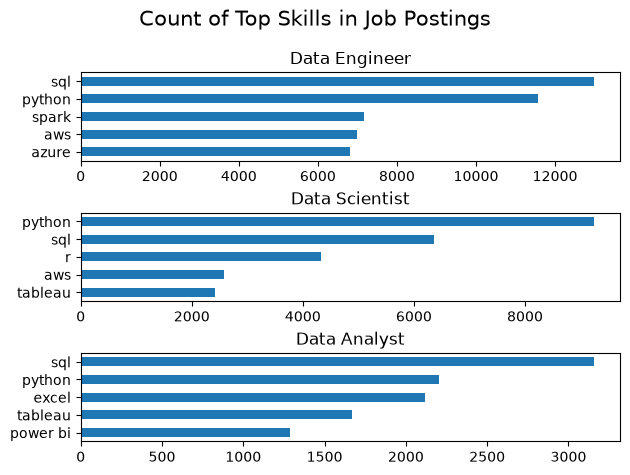

In [53]:
fig, ax = plt.subplots(len(job_titles), 1)

for i, item in enumerate(job_titles):
    df_plot = df_skill_count[df_skill_count['job_title_short'] == item].head(5).sort_values(by='skill_count')
    df_plot.plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i], legend=False, title=item)
    ax[i].set_ylabel('')
    
fig.suptitle('Count of Top Skills in Job Postings', fontsize=15)
fig.tight_layout(h_pad=0.5)

In [58]:
df_job_count = df_india['job_title_short'].value_counts().reset_index(name='total_jobs')

In [60]:
df_final = pd.merge(df_skill_count, df_job_count, how='left', on='job_title_short')

In [64]:
df_final['skill_percent'] = df_final['skill_count'] / df_final['total_jobs'] * 100

In [65]:
df_final

,job_skills,job_title_short,skill_count,total_jobs,skill_percent
0,sql,Data Engineer,12993,19062,68.161788
1,python,Data Engineer,11568,19062,60.686182
2,python,Data Scientist,9248,13279,69.643798
3,spark,Data Engineer,7157,19062,37.545903
4,aws,Data Engineer,6993,19062,36.685552
...,...,...,...,...,...
1684,angular.js,Data Scientist,1,13279,0.007531
1685,arch,Business Analyst,1,1887,0.052994
1686,mlpack,Data Engineer,1,19062,0.005246
1687,yarn,Senior Data Scientist,1,2486,0.040225


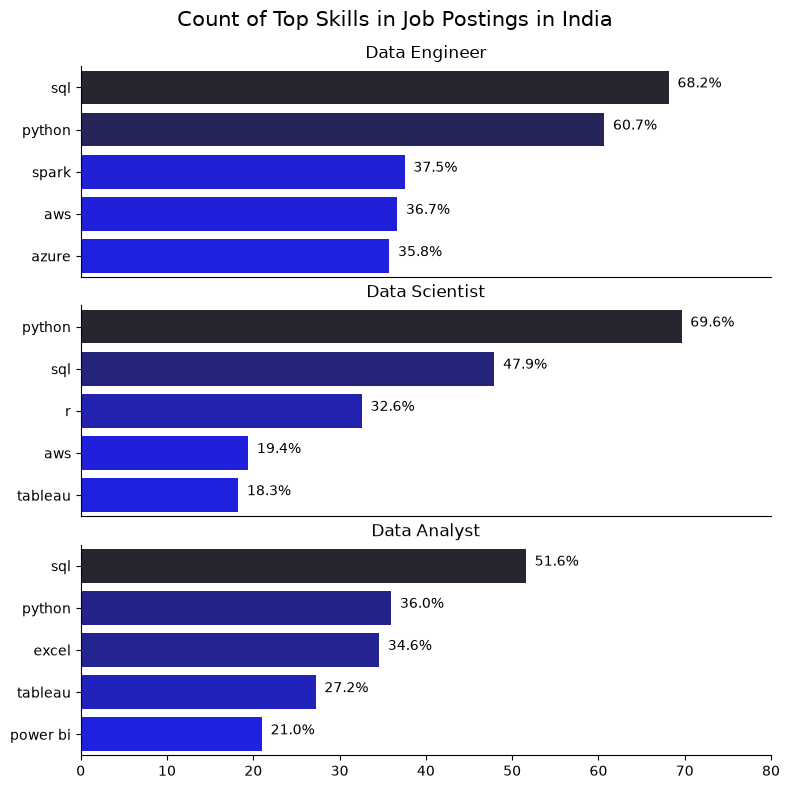

In [93]:
fig, ax = plt.subplots(len(job_titles), 1, figsize = (8, 8))

for i, item in enumerate(job_titles):
    df_plot = df_final[df_final['job_title_short'] == item].head(5).sort_values(by='skill_count')
    sns.barplot(df_plot, x='skill_percent', y='job_skills', ax=ax[i], hue='skill_count', palette='dark:b_r', legend=False)
    #df_plot.plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i], legend=False, title=item)
    ax[i].set_title(item)
    ax[i].set_ylabel('')
    ax[i].invert_yaxis()
    ax[i].set_xlabel('')
    ax[i].set_xlim(0, 80)
    sns.despine()
    
    for index, value in enumerate(df_plot['skill_percent']) :
        ax[i].text(value + 1, index, f'{value:.1f}%')
    
    if i != len(job_titles) - 1 :   
        ax[i].set_xticks([])
    
    
fig.suptitle('Count of Top Skills in Job Postings in India', fontsize=15)
fig.tight_layout(h_pad=0.5)